In [15]:
import pandas as pd
import json

In [16]:
df = pd.read_json("/home/razor/Documents/alzheimers-rag/data/corpus/alzheimers_corpus.jsonl", lines=True)

In [17]:
df.head()

,pmid,title,abstract,journal,year,text
0,42088846,Criterion and convergent validity of plasma bi...,<b>INTRODUCTION</b>: Despite expanding use of ...,"Alzheimer's & dementia (Amsterdam, Netherlands)",2026,Criterion and convergent validity of plasma bi...
1,42088780,Editorial: Genetic underpinnings of Alzheimer'...,NaN,Frontiers in genetics,2026,Editorial: Genetic underpinnings of Alzheimer'...
2,42088648,Insulin Resistance Across Cerebrovascular and ...,Insulin resistance (IR) Insulin resistance (IR...,Neuropsychiatric disease and treatment,2026,Insulin Resistance Across Cerebrovascular and ...
3,42088524,Body weight and waist circumference are differ...,Thyroid hormones (TH) and neurotransmitter ore...,Journal of clinical & translational endocrinology,2026,Body weight and waist circumference are differ...
4,42088504,Angiotensin-converting enzyme overexpression i...,"Angiotensin-converting enzyme (ACE), a dipepti...",Frontiers in immunology,2026,Angiotensin-converting enzyme overexpression i...


In [18]:
print("Total Papers: ", len(df))

Total Papers:  1000


In [19]:
missing_abstracts = df["abstract"].isna().sum()
missing_abstracts

np.int64(41)

In [20]:
df.dropna(subset=["abstract"], inplace=True)

In [21]:
print("Duplicate PMIDs: ", df["pmid"].duplicated().sum())

Duplicate PMIDs:  0


In [22]:
df["abstract_length"] = (df["abstract"].apply(len))

In [23]:
print(df["abstract_length"].describe())

count     959.000000
mean     1708.889468
std       565.745709
min        34.000000
25%      1332.000000
50%      1675.000000
75%      1962.000000
max      8153.000000
Name: abstract_length, dtype: float64


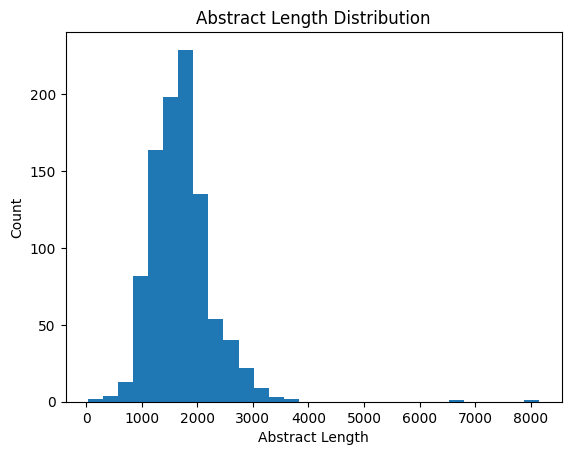

In [24]:
import matplotlib.pyplot as plt

plt.hist(df["abstract_length"], bins=30)
plt.xlabel("Abstract Length")
plt.ylabel("Count")
plt.title("Abstract Length Distribution")
plt.show()

In [25]:
year_counts = df["year"].value_counts().sort_index()
print(year_counts)

year
2025      5
2026    954
Name: count, dtype: int64


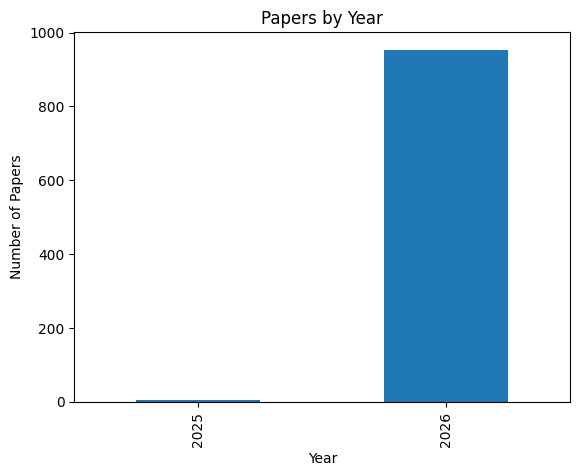

In [26]:
year_counts.plot(kind="bar")
plt.title("Papers by Year")
plt.xlabel("Year")
plt.ylabel("Number of Papers")
plt.show()

In [27]:
print(df["journal"].value_counts().head(10))

journal
Alzheimer's & dementia : the journal of the Alzheimer's Association    62
Journal of Alzheimer's disease : JAD                                   42
bioRxiv : the preprint server for biology                              32
International journal of molecular sciences                            23
Frontiers in aging neuroscience                                        14
medRxiv : the preprint server for health sciences                      14
Alzheimer's & dementia (Amsterdam, Netherlands)                        12
Molecular neurobiology                                                 12
Alzheimer's & dementia (New York, N. Y.)                               11
The journal of prevention of Alzheimer's disease                       11
Name: count, dtype: int64


In [28]:
print(
    df.sort_values("abstract_length")
    [["title", "abstract"]]
    .head(10)
)

                                                 title  \
114  Correction: Quansah et al. The Beneficial Effe...   
191  Tracking the turning point in Alzheimer's dise...   
869        A timeline of tau-mediated synaptotoxicity.   
621  A tanycytic route for tau clearance in Alzheim...   
243  High Nasopharyngeal SARS-CoV-2 Load and Delaye...   
353  Long-term clinical progression of Sneddon synd...   
766  White matter pathways mediating dorsolateral p...   
687  Neuropathologic Characterisation of Mitochondr...   
904  Cognition-enhancing drugs: current landscape, ...   
490  [Epidemiological studies of the association be...   

                                              abstract  
114                 In the original publication [...].  
191  A blood biomarker reveals the mechanistic shif...  
869  Oligomeric tau has been increasingly implicate...  
621  In a recent study, Sauvé et al. identified hyp...  
243  Autoantibodies neutralizing type I interferon ...  
353  Sneddon syndro

In [29]:
cleaned_records = df.to_dict(orient="records")

with open(
    "/home/razor/Documents/alzheimers-rag/data/corpus/alzheimers_cleaned.jsonl",
    "w",
    encoding="utf-8"
) as f:

    for record in cleaned_records:

        f.write(
            json.dumps(record) + "\n"
        )